# EXP-003 — Train lâu hơn với target cache sẵn (seed 1)
Train head trên cặp vector có sẵn: **feature CLIP** (cache 1 lần) + **target BLIP-2** (đã cache ở EXP-001, `exp001/full/targets/`). Không chạy CLIP/BLIP-2 khi train → mỗi epoch vài giây, **không cần A100**.

1. Cache feature CLIP (~5 phút, chỉ lần đầu).
2. Train 30 epoch, giữ head ở epoch 5 / 10 / 15 / 20 / 30.
3. Test từng mốc. **Epoch 5 = kiểm tra cache:** phải gần EXP-000 seed1 (|ΔUAR| ≤ 0.5) thì các mốc sau mới tin được.

Khác train gốc: target cache tính ở chế độ eval (không dropout), còn train gốc gọi `model.train()` nên dropout của Q-Former/T5 bật → target gốc có nhiễu. Mốc epoch 5 cho biết khác biệt này có đáng kể không.

# Cấu hình

In [1]:
SEED = 1
EPOCHS = 30
SAVE_EPOCHS = [5, 10, 15, 20, 30]     # test head ở các mốc này; mốc 5 = đúng số bước train gốc (kiểm tra cache)
LR = 1e-3
JOB_ID = f"exp003_cache_l14_seed{SEED}"
BRANCH = "exp/003-longer-training-cached"

INSTRUCTION = "Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image."
TRAIN_DATA = "/content/CAER-S_Face/train"
FACE_ZIP = "/content/drive/MyDrive/Datasets/CAERS_Face_train.zip"
TEST_ZIP = "/content/drive/MyDrive/Datasets/static_test_sets.zip"
PRE_DIR = "/content/drive/MyDrive/ExpCLIP_output/exp001/full"     # target đã cache ở EXP-001 (targets/chunk_*.npz)
CLIP_CACHE = f"{PRE_DIR}/clip_feats_l14.npz"                       # feature CLIP, tính 1 lần
OUT_DIR = "/content/drive/MyDrive/ExpCLIP_output/exp003"

import os, subprocess
def run(cmd):
    """Chạy lệnh shell, in output trực tiếp; lỗi thì dừng cell (khác với `!`)."""
    # bash + pipefail: lệnh có `| tee` vẫn báo lỗi nếu python lỗi
    p = subprocess.Popen("set -o pipefail; " + cmd, shell=True, executable="/bin/bash", text=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})  # in log ngay, không đợi hết
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"Lệnh lỗi (exit {p.returncode}) — xem output ở trên")

# Mount Drive & GPU

In [2]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(OUT_DIR, exist_ok=True)
# không nạp BLIP-2 → GPU nào cũng được (T4/L4/A100)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


# Clone repo (nhánh EXP-003)

In [3]:
if not os.path.isdir("/content/Exp-CLIP"):
    !git clone -b $BRANCH https://github.com/huongng389/Exp-CLIP.git /content/Exp-CLIP
%cd /content/Exp-CLIP
!git checkout $BRANCH && git pull
!git log --oneline -1   # ghi lại commit vào research_log

Cloning into '/content/Exp-CLIP'...
remote: Enumerating objects: 392, done.
remote: Counting objects: 100% (392/392), done.
remote: Compressing objects: 100% (126/126), done.
remote: Total 392 (delta 287), reused 366 (delta 262), pack-reused 0 (from 0)
Receiving objects: 100% (392/392), 32.19 MiB | 28.59 MiB/s, done.
Resolving deltas: 100% (287/287), done.
/content/Exp-CLIP
Already on 'exp/003-longer-training-cached'
Your branch is up to date with 'origin/exp/003-longer-training-cached'.
Already up to date.
ee3899f (HEAD -> exp/003-longer-training-cached, origin/exp/003-longer-training-cached) EXP-003: train from cached CLIP features and BLIP-2 targets


# Giải nén dữ liệu (train + test)

In [4]:
!mkdir -p /content/CAER-S_Face /content/static_test_sets
!unzip -q -n "$FACE_ZIP" -d /content/CAER-S_Face
!unzip -q -n "$TEST_ZIP" -d /content/static_test_sets
!ls /content/CAER-S_Face/train
!ls /content/static_test_sets

Angry  Disgust	Fear  Happy  Neutral  Sad  Surprise
AffectNet7  AffectNet8	FERPlus  RAFDB


# Cài dependencies (venv310)\ntorch 2.0.1 + lavis: dùng cho target, proto, weight, train, test.

In [5]:
!sudo apt-get -qq update > /dev/null
!sudo apt-get -qq install -y python3.10 python3.10-venv python3.10-distutils > /dev/null
!python3.10 -m venv /content/venv310
!/content/venv310/bin/pip install -q --upgrade pip
!/content/venv310/bin/pip install -q --no-cache-dir torch==2.0.1 torchvision==0.15.2 torchaudio==2.0.2 --index-url https://download.pytorch.org/whl/cu118
!/content/venv310/bin/pip install -q --no-cache-dir transformers tqdm regex pyyaml pandas pydantic click timm einops
!/content/venv310/bin/pip install -q --no-cache-dir salesforce-lavis
# phải cài SAU lavis: lavis kéo numpy 2.x / opencv mới
!/content/venv310/bin/pip install -q --no-cache-dir "numpy<2" "opencv-python==4.10.0.84" "opencv-python-headless==4.10.0.84"
!/content/venv310/bin/pip install -q --no-cache-dir matplotlib scikit-learn
!/content/venv310/bin/python -c "import numpy, torch, lavis, sklearn; print('numpy', numpy.__version__, '| torch', torch.__version__, '| cuda', torch.cuda.is_available())"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 7.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 24.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Instal

# Cache feature CLIP
Cùng transform với train gốc (Resize 224 + ToTensor). Đã có trên Drive thì bỏ qua.

In [6]:
if not os.path.exists(CLIP_CACHE):
    run(f'/content/venv310/bin/python tools/cache_clip_features.py --train-data {TRAIN_DATA} --out {CLIP_CACHE} '
        f'--load-model CLIP_L14 --batch-size 256 --workers 8')
!ls -lh "$CLIP_CACHE"; ls "$PRE_DIR/targets" | wc -l

-rw------- 1 root root 75M Oct 14 07:10 /content/drive/MyDrive/ExpCLIP_output/exp001/full/clip_feats_l14.npz
765


# Train 30 epoch từ cache
Cấu hình như EXP-000 (lr 1e-3, batch 512, SGD), chỉ khác số epoch. `--milestones 1000` = không giảm lr (bản gốc 5 epoch cũng không giảm). Bị ngắt thì chạy lại cell này (tự resume).

In [7]:
resume = f"{OUT_DIR}/{JOB_ID}-resume.pth"
run(f'/content/venv310/bin/python train.py '
    f'--epochs {EPOCHS} --batch-size 512 --batch-size-test-image 512 --batch-size-test-video 64 '
    f'--lr {LR} --weight-decay 1e-4 --momentum 0.9 --print-freq 1000 --milestones 1000 --seed {SEED} '
    f'--job-id {JOB_ID} --instruction "{INSTRUCTION}" --load-model CLIP_L14 '
    f'--cache-clip {CLIP_CACHE} --cache-targets {PRE_DIR}/targets '
    f'--save-epochs {" ".join(map(str, SAVE_EPOCHS))} --extra-checkpoint-dir {OUT_DIR}'
    + (f' --resume {resume}' if os.path.exists(resume) else ''))

Training date:  26-10-14 07:21
************************
workers = 8
epochs = 30
batch_size = 512
batch_size_test_image = 512
batch_size_test_video = 64
lr = 0.001
weight_decay = 0.0001
momentum = 0.9
print_freq = 1000
milestones = [1000]
seed = 1
job_id = exp003_cache_l14_seed1
instruction = Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image.
load_model = CLIP_L14
extra_checkpoint_dir = /content/drive/MyDrive/ExpCLIP_output/exp003
train_data = /data/EECS-IoannisLab/datasets/Static_FER_Datasets/CAERS_Face/train
sample_weights = None
cache_clip = /content/drive/MyDrive/ExpCLIP_output/exp001/full/clip_feats_l14.npz
cache_targets = /content/drive/MyDrive/ExpCLIP_output/exp001/full/targets
save_epochs = [5, 10, 15, 20, 30]
resume = /content/drive/MyDrive/ExpCLIP_output/exp003/exp003_cache_l14_seed1-resume.pth
************************

  0%|                                               | 0.00/890M [00:00<?, ?iB/s]
 

# Test zero-shot từng mốc

In [8]:
!mkdir -p checkpoint log
for e in SAVE_EPOCHS:
    job = f"{JOB_ID}-e{e}"
    if not os.path.exists(f"checkpoint/{job}-model.pth"):
        !cp "$OUT_DIR/$job-model.pth" checkpoint/
    print(f"=============== epoch {e}")
    run(f'/content/venv310/bin/python test.py --load-model CLIP_L14 --job-id {job} '
        f'--data-root /content/static_test_sets 2>&1 | tee log/{job}-test.txt')
    !cp log/$job-test.txt "$OUT_DIR/"

=============== epoch 5
************************
load_model = CLIP_L14
job_id = exp003_cache_l14_seed1-e5
data_root = /content/static_test_sets
************************
************************************************************************** Zero-shot Prompt Type:  Class Name
******************** Static FER Zero-shot Performance ********************
************************* RAFDB
UAR/WAR: 50.79/56.65
************************* AffectNet7
UAR/WAR: 42.34/42.34
************************* AffectNet8
UAR/WAR: 36.73/36.73
************************* FERPlus
UAR/WAR: 37.78/45.31
************************************************************************** Zero-shot Prompt Type:  An Expression of Name
******************** Static FER Zero-shot Performance ********************
************************* RAFDB
UAR/WAR: 56.42/63.85
************************* AffectNet7
UAR/WAR: 44.00/44.00
************************* AffectNet8
UAR/WAR: 38.38/38.38
************************* FERPlus
UAR/WAR: 39.57/52.76
**

# So sánh
Bảng 1: Ensemble Five theo epoch (UAR). Bảng 2: đủ 5 prompt, Δ so với EXP-000 seed1 ở từng mốc.

In [9]:
import re, pandas as pd
REF = pd.DataFrame([{"prompt": "Class Name", "dataset": "RAFDB", "src": "EXP-000 seed1", "UAR": 50.36, "WAR": 56.58}, {"prompt": "Class Name", "dataset": "AffectNet7", "src": "EXP-000 seed1", "UAR": 42.51, "WAR": 42.51}, {"prompt": "Class Name", "dataset": "AffectNet8", "src": "EXP-000 seed1", "UAR": 36.95, "WAR": 36.95}, {"prompt": "Class Name", "dataset": "FERPlus", "src": "EXP-000 seed1", "UAR": 38.27, "WAR": 45.45}, {"prompt": "An Expression of Name", "dataset": "RAFDB", "src": "EXP-000 seed1", "UAR": 56.73, "WAR": 64.05}, {"prompt": "An Expression of Name", "dataset": "AffectNet7", "src": "EXP-000 seed1", "UAR": 44.0, "WAR": 44.0}, {"prompt": "An Expression of Name", "dataset": "AffectNet8", "src": "EXP-000 seed1", "UAR": 38.33, "WAR": 38.33}, {"prompt": "An Expression of Name", "dataset": "FERPlus", "src": "EXP-000 seed1", "UAR": 39.99, "WAR": 52.92}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "RAFDB", "src": "EXP-000 seed1", "UAR": 54.94, "WAR": 65.12}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet7", "src": "EXP-000 seed1", "UAR": 43.97, "WAR": 43.97}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet8", "src": "EXP-000 seed1", "UAR": 38.02, "WAR": 38.02}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "FERPlus", "src": "EXP-000 seed1", "UAR": 36.63, "WAR": 48.89}, {"prompt": "Expression Ensemble Five", "dataset": "RAFDB", "src": "EXP-000 seed1", "UAR": 58.88, "WAR": 66.88}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet7", "src": "EXP-000 seed1", "UAR": 44.09, "WAR": 44.09}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet8", "src": "EXP-000 seed1", "UAR": 39.23, "WAR": 39.23}, {"prompt": "Expression Ensemble Five", "dataset": "FERPlus", "src": "EXP-000 seed1", "UAR": 40.65, "WAR": 51.47}, {"prompt": "Expression Ensemble Ten", "dataset": "RAFDB", "src": "EXP-000 seed1", "UAR": 57.73, "WAR": 65.91}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet7", "src": "EXP-000 seed1", "UAR": 44.94, "WAR": 44.94}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet8", "src": "EXP-000 seed1", "UAR": 39.55, "WAR": 39.55}, {"prompt": "Expression Ensemble Ten", "dataset": "FERPlus", "src": "EXP-000 seed1", "UAR": 40.45, "WAR": 49.29}, {"prompt": "Class Name", "dataset": "RAFDB", "src": "EXP-000 mean3", "UAR": 50.23, "WAR": 54.56}, {"prompt": "Class Name", "dataset": "AffectNet7", "src": "EXP-000 mean3", "UAR": 41.47, "WAR": 41.47}, {"prompt": "Class Name", "dataset": "AffectNet8", "src": "EXP-000 mean3", "UAR": 35.76, "WAR": 35.76}, {"prompt": "Class Name", "dataset": "FERPlus", "src": "EXP-000 mean3", "UAR": 38.58, "WAR": 45.82}, {"prompt": "An Expression of Name", "dataset": "RAFDB", "src": "EXP-000 mean3", "UAR": 55.34, "WAR": 62.0}, {"prompt": "An Expression of Name", "dataset": "AffectNet7", "src": "EXP-000 mean3", "UAR": 43.79, "WAR": 43.79}, {"prompt": "An Expression of Name", "dataset": "AffectNet8", "src": "EXP-000 mean3", "UAR": 38.4, "WAR": 38.4}, {"prompt": "An Expression of Name", "dataset": "FERPlus", "src": "EXP-000 mean3", "UAR": 38.89, "WAR": 51.62}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "RAFDB", "src": "EXP-000 mean3", "UAR": 55.64, "WAR": 64.78}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet7", "src": "EXP-000 mean3", "UAR": 44.39, "WAR": 44.39}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet8", "src": "EXP-000 mean3", "UAR": 38.08, "WAR": 38.08}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "FERPlus", "src": "EXP-000 mean3", "UAR": 37.95, "WAR": 49.17}, {"prompt": "Expression Ensemble Five", "dataset": "RAFDB", "src": "EXP-000 mean3", "UAR": 58.07, "WAR": 65.32}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet7", "src": "EXP-000 mean3", "UAR": 44.17, "WAR": 44.17}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet8", "src": "EXP-000 mean3", "UAR": 38.84, "WAR": 38.84}, {"prompt": "Expression Ensemble Five", "dataset": "FERPlus", "src": "EXP-000 mean3", "UAR": 41.55, "WAR": 53.41}, {"prompt": "Expression Ensemble Ten", "dataset": "RAFDB", "src": "EXP-000 mean3", "UAR": 57.19, "WAR": 64.6}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet7", "src": "EXP-000 mean3", "UAR": 44.97, "WAR": 44.97}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet8", "src": "EXP-000 mean3", "UAR": 39.45, "WAR": 39.45}, {"prompt": "Expression Ensemble Ten", "dataset": "FERPlus", "src": "EXP-000 mean3", "UAR": 42.17, "WAR": 49.46}, {"prompt": "Class Name", "dataset": "RAFDB", "src": "paper", "UAR": 58.7, "WAR": 65.37}, {"prompt": "Class Name", "dataset": "AffectNet7", "src": "paper", "UAR": 44.27, "WAR": 44.27}, {"prompt": "Class Name", "dataset": "AffectNet8", "src": "paper", "UAR": 38.44, "WAR": 38.43}, {"prompt": "Class Name", "dataset": "FERPlus", "src": "paper", "UAR": 48.28, "WAR": 55.42}, {"prompt": "An Expression of Name", "dataset": "RAFDB", "src": "paper", "UAR": 58.7, "WAR": 65.37}, {"prompt": "An Expression of Name", "dataset": "AffectNet7", "src": "paper", "UAR": 44.27, "WAR": 44.27}, {"prompt": "An Expression of Name", "dataset": "AffectNet8", "src": "paper", "UAR": 38.44, "WAR": 38.43}, {"prompt": "An Expression of Name", "dataset": "FERPlus", "src": "paper", "UAR": 48.28, "WAR": 55.42}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "RAFDB", "src": "paper", "UAR": 58.7, "WAR": 65.37}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet7", "src": "paper", "UAR": 44.27, "WAR": 44.27}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "AffectNet8", "src": "paper", "UAR": 38.44, "WAR": 38.43}, {"prompt": "A Photo of A Face with An Expression of Name", "dataset": "FERPlus", "src": "paper", "UAR": 48.28, "WAR": 55.42}, {"prompt": "Expression Ensemble Five", "dataset": "RAFDB", "src": "paper", "UAR": 58.7, "WAR": 65.37}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet7", "src": "paper", "UAR": 44.27, "WAR": 44.27}, {"prompt": "Expression Ensemble Five", "dataset": "AffectNet8", "src": "paper", "UAR": 38.44, "WAR": 38.43}, {"prompt": "Expression Ensemble Five", "dataset": "FERPlus", "src": "paper", "UAR": 48.28, "WAR": 55.42}, {"prompt": "Expression Ensemble Ten", "dataset": "RAFDB", "src": "paper", "UAR": 58.7, "WAR": 65.37}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet7", "src": "paper", "UAR": 44.27, "WAR": 44.27}, {"prompt": "Expression Ensemble Ten", "dataset": "AffectNet8", "src": "paper", "UAR": 38.44, "WAR": 38.43}, {"prompt": "Expression Ensemble Ten", "dataset": "FERPlus", "src": "paper", "UAR": 48.28, "WAR": 55.42}])

def parse(path):
    rows, prompt, dataset = [], None, None
    for line in open(path):
        if "Prompt Type:" in line:
            prompt = line.split("Prompt Type:")[1].strip()
        elif re.match(r"^\*+ (RAFDB|AffectNet7|AffectNet8|FERPlus)$", line.strip()):
            dataset = line.strip().split()[-1]
        elif line.startswith("UAR/WAR:"):
            uar, war = map(float, line.split(":")[1].strip().split("/"))
            rows.append(dict(prompt=prompt, dataset=dataset, UAR=uar, WAR=war))
    return pd.DataFrame(rows)

res = pd.concat([parse(f"log/{JOB_ID}-e{e}-test.txt").assign(epoch=e) for e in SAVE_EPOCHS])
res.to_csv(f"{OUT_DIR}/{JOB_ID}-results.csv", index=False)
base = REF[REF.src == "EXP-000 seed1"].set_index(["prompt", "dataset"])
paper = REF[(REF.src == "paper") & (REF.prompt == "Expression Ensemble Five")].set_index("dataset")
pd.set_option("display.width", 250)

ens = res[res.prompt == "Expression Ensemble Five"].pivot(index="epoch", columns="dataset", values="UAR")
ens = ens[["RAFDB", "AffectNet7", "AffectNet8", "FERPlus"]]
b5 = base.loc["Expression Ensemble Five"].UAR
show = pd.concat({"UAR": ens, "Δ vs EXP-000 seed1": (ens - b5).round(2), "Δ vs paper": (ens - paper.UAR).round(2)}, axis=1)
display(show)

full = res.merge(base.UAR.rename("UAR_base").reset_index(), on=["prompt", "dataset"])
full["Δ"] = (full.UAR - full.UAR_base).round(2)
display(full.pivot_table(index=["prompt", "dataset"], columns="epoch", values="Δ", sort=False))

UAR                               Δ vs EXP-000 seed1                               Δ vs paper                              
dataset  RAFDB AffectNet7 AffectNet8 FERPlus              RAFDB AffectNet7 AffectNet8 FERPlus      RAFDB AffectNet7 AffectNet8 FERPlus
epoch                                                                                                                                 
5        58.64      44.20      39.02   40.56              -0.24       0.11      -0.21   -0.09      -0.06      -0.07       0.58   -7.72
10       56.73      43.97      38.42   42.05              -2.15      -0.12      -0.81    1.40      -1.97      -0.30      -0.02   -6.23
15       55.33      44.14      38.08   44.08              -3.55       0.05      -1.15    3.43      -3.37      -0.13      -0.36   -4.20
20       54.61      44.14      37.95   45.10              -4.27       0.05      -1.28    4.45      -4.09      -0.13      -0.49   -3.18
30       53.68      44.20      37.85   44.96              -5.20       0.11      -1.38    4.31      -5.02      -0.07      -0.59   -3.32

epoch                                                      5     10    15    20    30
prompt                                       dataset                                 
Class Name                                   RAFDB       0.43  2.29  3.00  3.25  2.65
                                             AffectNet7 -0.17  0.80  1.09  1.55  1.92
                                             AffectNet8 -0.22  0.05  0.13  0.15  0.38
                                             FERPlus    -0.49  0.71  1.96  2.52  4.80
An Expression of Name                        RAFDB      -0.31 -1.20 -2.10 -2.62 -3.39
                                             AffectNet7  0.00  0.40  0.31  0.46  0.49
                                             AffectNet8  0.05 -0.03 -0.30 -0.30 -0.28
                                             FERPlus    -0.42  0.68  3.07  4.47  6.13
A Photo of A Face with An Expression of Name RAFDB      -0.39 -2.32 -3.35 -4.02 -5.27
                                             AffectNet7  0.06 -0.57 -1.28 -1.80 -1.91
                                             AffectNet8  0.00 -0.80 -1.79 -2.22 -2.52
                                             FERPlus    -0.36 -0.46  2.57  3.82  3.94
Expression Ensemble Five                     RAFDB      -0.24 -2.15 -3.55 -4.27 -5.20
                                             AffectNet7  0.11 -0.12  0.05  0.05  0.11
                                             AffectNet8 -0.21 -0.81 -1.15 -1.28 -1.38
                                             FERPlus    -0.09  1.40  3.43  4.45  4.31
Expression Ensemble Ten                      RAFDB      -0.28 -1.80 -2.73 -3.57 -5.05
                                             AffectNet7 -0.11 -0.40 -0.48 -0.80 -0.85
                                             AffectNet8 -0.17 -0.85 -1.30 -1.55 -1.47
                                             FERPlus    -0.17  0.33  2.23  3.47  3.67

# Log train
Train accuracy / loss theo epoch (train gốc: 27.6% ở epoch 5).

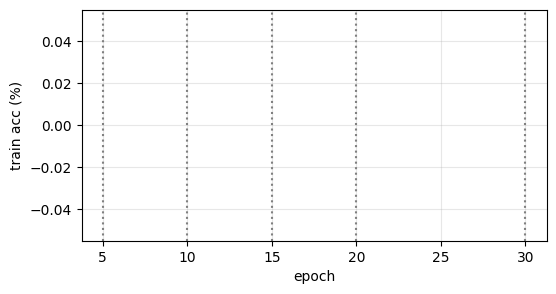

{}


In [10]:
import matplotlib.pyplot as plt
acc = [float(l.split(":")[1]) for l in open(f"log/{JOB_ID}-log.txt") if l.startswith("The best accuracy")]
plt.figure(figsize=(6, 3)); plt.plot(range(1, len(acc) + 1), acc); plt.xlabel("epoch"); plt.ylabel("train acc (%)")
for e in SAVE_EPOCHS: plt.axvline(e, ls=":", c="gray")
plt.grid(alpha=.3); plt.show()
print({e: round(acc[e - 1], 2) for e in SAVE_EPOCHS if e <= len(acc)})